# Validacion de Dynamical Decoupling en QPU — v4 (relevos y resultados optimizados)

**Un solo job** que mide, en el mismo lote y con el mismo layout fisico:

| Bloque | Circuitos | Para que |
|---|---|---|
| Calibracion de lectura | 2 (todo en 0, todo en 1) | Mitigar ⟨X⟩/⟨Y⟩ y tener el piso de lectura **de cada qubit** |
| Barrido principal | 3 protocolos × ~16 tiempos × bases X e Y | Coherencia en cuadratura \|ρ01\| = √(⟨X⟩²+⟨Y⟩²): elimina la oscilacion por detuning |
| Referencias de relevo | objetivo inactivo / objetivo en \|1⟩ a 3 tiempos | Prueba **pareada** de transferencia de poblacion a cada vecino |
| Espectadores en \|1⟩ (ZZ) | libre y CPMG a 3 tiempos | Medir cuanto afecta el estado de los vecinos a la fase del objetivo y si DD lo cancela |

## Que cambia respecto a v1-v3
1. **Detuning sin aliasing.** v2/v3 muestreaban cada 26-130 µs; el detuning real (~27 kHz) aparecia como 54 kHz y el T2 libre salia en 62 µs. Ahora hay un tramo denso (≤ 5 µs de paso) y lectura en X e Y.
2. **Ajustes fisicos.** C = 0 fijo (la coherencia decae a 0), ponderado por ruido de disparo, error inflado por √χ² si hay deriva. Esto quita la degeneracion T2↔C que daba barras de error mayores que el valor.
3. **Relevos bien planteados.** Se cuentan todas las compuertas de 2 qubits (un SWAP transpilado son 3 CZ), se verifica el layout inicial y final, y la poblacion de cada vecino se compara con **su propia** linea base (objetivo inactivo), con prueba de dos proporciones y correccion de Bonferroni.
4. **Tiempos alineados a dt.** Libre, CPMG y XY4 tienen exactamente el mismo tiempo de espera, sin los `UserWarning` de redondeo, y se reporta t efectivo con la duracion de los pulsos.
5. **Orden aleatorio** de circuitos para que la deriva lenta no se correlacione con t.
6. **Shots por circuito** (PUBs con shots propios) y **freno de tiempo QPU** antes de enviar.
7. **Modo `reuse`**: reanaliza un job ya ejecutado sin volver a hacer cola. **Modo `sim`**: prueba todo gratis con `FakeFez`.

## Requisitos (Kaggle)
Internet ON · secreto `IBM_QUANTUM_TOKEN` · reiniciar el kernel si lo pide tras `pip`.


## 1. Instalacion

In [48]:
%pip install -q "qiskit>=1.3" "qiskit-ibm-runtime>=0.30" qiskit-aer matplotlib scipy
print("OK")

Note: you may need to restart the kernel to use updated packages.
OK


## 2. Paquete `ddqpu` (embebido)
Esta celda escribe el paquete del repositorio en `./ddqpu/`. Si clonaste el repo, puedes omitirla y hacer `pip install -e .`.

In [49]:
import pathlib, importlib, sys
_FILES = {}
_FILES['__init__.py'] = '"""ddqpu: validacion de Dynamical Decoupling en QPU IBM con control de relevos."""\n__version__ = "4.0.0"\nfrom .circuits import *  # noqa\nfrom .analysis import *  # noqa\nfrom .backend_utils import *  # noqa\nfrom .experiment import *  # noqa\n'
_FILES['circuits.py'] = '"""Construccion de circuitos DD con espectadores (vecinos + control) y tiempos alineados a dt.\n\nConvencion de bits: bit 0 = objetivo, bits 1..k = vecinos, ultimo bit = control lejano.\nTodos los qubits del layout se miden en todos los circuitos, asi cada circuito aporta datos\nde "relevo" (poblacion en espectadores) sin coste extra de circuitos.\n"""\nfrom __future__ import annotations\n\nfrom dataclasses import dataclass, asdict, field\nfrom typing import List, Sequence\n\nimport numpy as np\nfrom qiskit import QuantumCircuit\n\nPROTOCOLS = ("free", "cpmg", "xy4")\nBASES = ("X", "Y")\n\n\n@dataclass\nclass Timing:\n    """Restricciones de tiempo del backend (todo en unidades de dt)."""\n    dt: float                 # segundos por muestra\n    granularity: int = 16     # multiplo obligatorio de duracion de delay\n    min_length: int = 64\n    x_duration_dt: int = 0    # duracion de un pulso X/Y (para t_efectivo)\n\n    def us_to_dt(self, t_us: float) -> int:\n        """Redondea t_us al multiplo de granularidad mas cercano (evita los UserWarning de redondeo\n        y garantiza que libre/CPMG/XY4 tengan exactamente el mismo tiempo de espera)."""\n        n = int(round(t_us * 1e-6 / self.dt))\n        g = max(int(self.granularity), 1)\n        return int(round(n / g) * g)\n\n    def dt_to_us(self, n: int) -> float:\n        return n * self.dt * 1e6\n\n\ndef timing_from_backend(backend) -> Timing:\n    target = backend.target\n    dt = float(target.dt or backend.dt)\n    gran, minlen = 16, 64\n    try:\n        tc = target.timing_constraints()\n        gran, minlen = int(tc.granularity), int(tc.min_length)\n    except Exception:\n        pass\n    xdur = 0\n    try:\n        q0 = next(iter(target["x"].keys()))\n        d = target["x"][q0].duration\n        if d:\n            xdur = int(round(d / dt))\n    except Exception:\n        pass\n    return Timing(dt=dt, granularity=max(gran, 1), min_length=max(minlen, 1), x_duration_dt=xdur)\n\n\n@dataclass\nclass CircuitSpec:\n    """Metadatos de un circuito del lote (se serializan en el manifiesto del job)."""\n    kind: str                 # main | cal0 | cal1 | idle | exc1 | zz | nsweep\n    protocol: str = "none"    # free | cpmg | xy4 | none\n    basis: str = "Z"          # X | Y | Z\n    t_us: float = 0.0         # tiempo de espera nominal alineado a dt\n    t_eff_us: float = 0.0     # tiempo total incluyendo pulsos DD\n    n_pulses: int = 0\n    spectator_state: str = "0"  # estado preparado en los vecinos\n    shots: int = 0\n    extra: dict = field(default_factory=dict)\n\n    def to_dict(self):\n        return asdict(self)\n\n\ndef _pulse_sequence(protocol: str, n_cpmg: int, n_xy4_cycles: int) -> List[str]:\n    if protocol == "cpmg":\n        return ["x"] * n_cpmg\n    if protocol == "xy4":\n        return ["x", "y", "x", "y"] * max(n_xy4_cycles, 1)\n    return []\n\n\ndef _dd_block(qc: QuantumCircuit, q: int, total_dt: int, pulses: Sequence[str], timing: Timing):\n    """tau/2 - P - tau - P - ... - P - tau/2, con todos los delays en dt y multiplos de granularidad.\n    El residuo de redondeo se absorbe en el ultimo tramo para conservar el tiempo total exacto."""\n    if total_dt <= 0:\n        return\n    if not pulses:\n        qc.delay(total_dt, q, unit="dt")\n        return\n    n = len(pulses)\n    g = timing.granularity\n    half = int((total_dt / (2 * n)) // g * g)\n    full = 2 * half\n    used = half + full * (n - 1) + half\n    last = half + (total_dt - used)\n    if half > 0:\n        qc.delay(half, q, unit="dt")\n    for i, p in enumerate(pulses):\n        getattr(qc, p)(q)\n        seg = full if i < n - 1 else last\n        if seg > 0:\n            qc.delay(seg, q, unit="dt")\n\n\ndef build_coherence_circuit(\n    protocol: str,\n    t_us: float,\n    basis: str,\n    n_spectators: int,\n    timing: Timing,\n    n_cpmg: int = 6,\n    n_xy4_cycles: int = 2,\n    spectator_state: str = "0",\n    n_neighbors: int = 2,\n):\n    """Objetivo en |+>, espera con/sin DD, lectura en base X o Y. Espectadores inactivos."""\n    n = 1 + n_spectators\n    t_dt = timing.us_to_dt(t_us)\n    pulses = _pulse_sequence(protocol, n_cpmg, n_xy4_cycles) if t_dt > 0 else []\n    qc = QuantumCircuit(n, n, name=f"{protocol}_{basis}_{t_dt}dt_s{spectator_state}")\n    if spectator_state == "1":\n        for k in range(1, 1 + n_neighbors):\n            qc.x(k)\n    qc.h(0)\n    qc.barrier()\n    _dd_block(qc, 0, t_dt, pulses, timing)\n    qc.barrier()\n    if basis == "Y":\n        qc.sdg(0)\n    qc.h(0)\n    qc.measure(range(n), range(n))\n    t_eff = timing.dt_to_us(t_dt + len(pulses) * timing.x_duration_dt)\n    spec = CircuitSpec(kind="main" if spectator_state == "0" else "zz", protocol=protocol, basis=basis,\n                       t_us=timing.dt_to_us(t_dt), t_eff_us=t_eff, n_pulses=len(pulses),\n                       spectator_state=spectator_state)\n    return qc, spec\n\n\ndef build_readout_cal(n_qubits: int, state: str):\n    qc = QuantumCircuit(n_qubits, n_qubits, name=f"cal{state}")\n    if state == "1":\n        qc.x(range(n_qubits))\n    qc.barrier()\n    qc.measure(range(n_qubits), range(n_qubits))\n    return qc, CircuitSpec(kind=f"cal{state}")\n\n\ndef build_relay_reference(t_us: float, n_spectators: int, timing: Timing, target_state: str):\n    """Referencia pareada para relevos.\n    target_state=\'0\' -> objetivo inactivo (linea base de cada vecino a igual t).\n    target_state=\'1\' -> objetivo excitado |1> (caso mas sensible a transferencia por intercambio)."""\n    n = 1 + n_spectators\n    t_dt = timing.us_to_dt(t_us)\n    qc = QuantumCircuit(n, n, name=f"relay_t{target_state}_{t_dt}dt")\n    if target_state == "1":\n        qc.x(0)\n    qc.barrier()\n    if t_dt > 0:\n        qc.delay(t_dt, 0, unit="dt")\n    qc.barrier()\n    qc.measure(range(n), range(n))\n    kind = "idle" if target_state == "0" else "exc1"\n    return qc, CircuitSpec(kind=kind, t_us=timing.dt_to_us(t_dt), t_eff_us=timing.dt_to_us(t_dt))\n\n\ndef default_time_grid(t2_ref_us: float, fractions: Sequence[float] | None = None, t_max_us: float = 450.0,\n                      dense_us: Sequence[float] | None = None):\n    """Rejilla en dos tramos:\n    - tramo denso absoluto (paso <= 5 us hasta 40 us): resuelve la fase sin aliasing para |detuning| < ~100 kHz\n      (en v2/v3 el paso era de 26-130 us y el detuning real de ~27 kHz aparecia como ~54 kHz);\n    - tramo escalado a T2 calibrado (0.2x .. 1.6x): resuelve la envolvente y beta."""\n    if dense_us is None:\n        dense_us = [2, 5, 10, 15, 20, 25, 30, 40]\n    if fractions is None:\n        fractions = [0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.3, 1.6]\n    grid = set(float(t) for t in dense_us)\n    grid |= set(round(min(f * t2_ref_us, t_max_us), 1) for f in fractions)\n    grid = sorted(g for g in grid if g > 0)\n    # elimina puntos casi duplicados (< 3 us)\n    out = []\n    for g in grid:\n        if not out or g - out[-1] >= 3.0:\n            out.append(g)\n    return out\n\n\ndef expected_parity_z(qc: QuantumCircuit) -> int:\n    """Utilidad para pruebas: numero de X/Y en el objetivo (debe ser par para volver a |+>)."""\n    return sum(1 for ins in qc.data if ins.operation.name in ("x", "y") and qc.find_bit(ins.qubits[0]).index == 0)\n\n\n__all__ = [\n    "PROTOCOLS", "BASES", "Timing", "timing_from_backend", "CircuitSpec",\n    "build_coherence_circuit", "build_readout_cal", "build_relay_reference", "default_time_grid",\n]\n_ = np  # numpy reservado para extensiones\n'
_FILES['backend_utils.py'] = '"""Seleccion de qubits, layout de espectadores, transpilacion verificada y estimacion de tiempo QPU."""\nfrom __future__ import annotations\n\nimport os\nfrom dataclasses import dataclass, asdict\nfrom typing import Dict, List, Optional\n\nimport numpy as np\n\nTWO_Q_GATES = {"cz", "ecr", "cx", "swap", "rzz", "iswap", "cy", "cp", "rzx"}\n\n\ndef get_token() -> str:\n    try:\n        from kaggle_secrets import UserSecretsClient  # type: ignore\n        t = UserSecretsClient().get_secret("IBM_QUANTUM_TOKEN")\n        if t:\n            return t.strip()\n    except Exception:\n        pass\n    t = os.environ.get("QISKIT_IBM_TOKEN") or os.environ.get("IBM_QUANTUM_TOKEN")\n    if not t:\n        raise RuntimeError("Configure el secreto IBM_QUANTUM_TOKEN (Kaggle) o la variable QISKIT_IBM_TOKEN")\n    return t.strip()\n\n\ndef get_service(channel: str = "ibm_cloud", instance: Optional[str] = "open-instance"):\n    """Crea el servicio sin escribir el token en disco (save_account no es necesario en cada corrida)."""\n    from qiskit_ibm_runtime import QiskitRuntimeService\n    kw = {"channel": channel, "token": get_token()}\n    if instance:\n        kw["instance"] = instance\n    return QiskitRuntimeService(**kw)\n\n\n@dataclass\nclass QubitInfo:\n    q: int\n    t1_us: float\n    t2_us: float\n    sx_err: float\n    ro_err: float\n    score: float\n\n\ndef _qubit_info(backend, q: int) -> Optional[QubitInfo]:\n    tgt = backend.target\n    try:\n        qp = tgt.qubit_properties[q]\n        t1 = (qp.t1 or 0.0) * 1e6\n        t2 = (qp.t2 or 0.0) * 1e6\n    except Exception:\n        return None\n    if t2 <= 0 or t1 <= 0:\n        return None\n\n    def err(op):\n        try:\n            e = tgt[op][(q,)].error\n            return float(e) if e is not None else None\n        except Exception:\n            return None\n\n    sx = err("sx") or err("x") or 1e-2\n    ro = err("measure") or 5e-2\n    # T2 > 2*T1 no es fisico: calibracion sospechosa, se recorta\n    t2_eff = min(t2, 2.0 * t1)\n    score = t2_eff / (1.0 + 50.0 * sx + 10.0 * ro)\n    return QubitInfo(q, t1, t2, sx, ro, score)\n\n\ndef rank_qubits(backend, top: int = 8) -> List[QubitInfo]:\n    rows = [r for q in range(backend.num_qubits) if (r := _qubit_info(backend, q))]\n    rows.sort(key=lambda r: -r.score)\n    return rows[:top] if top else rows\n\n\ndef bfs_distances(backend, source: int) -> Dict[int, int]:\n    adj: Dict[int, set] = {q: set() for q in range(backend.num_qubits)}\n    for a, b in backend.coupling_map.get_edges():\n        adj[a].add(b)\n        adj[b].add(a)\n    dist = {source: 0}\n    frontier = [source]\n    while frontier:\n        nxt = []\n        for u in frontier:\n            for v in adj[u]:\n                if v not in dist:\n                    dist[v] = dist[u] + 1\n                    nxt.append(v)\n        frontier = nxt\n    return dist\n\n\n@dataclass\nclass Layout:\n    target: int\n    target_t2_us: float\n    target_t1_us: float\n    neighbors: List[int]\n    control: int\n    control_distance: int\n\n    @property\n    def physical(self) -> List[int]:\n        return [self.target] + list(self.neighbors) + [self.control]\n\n    def to_dict(self):\n        d = asdict(self)\n        d["physical"] = self.physical\n        return d\n\n\ndef choose_layout(backend, force_target: Optional[int] = None, n_neighbors: int = 2,\n                  min_control_distance: int = 4) -> Layout:\n    ranked = rank_qubits(backend, top=0)\n    info = {r.q: r for r in ranked}\n    if force_target is not None:\n        tq = int(force_target)\n    else:\n        tq = ranked[0].q\n    ti = info.get(tq) or _qubit_info(backend, tq)\n    dist = bfs_distances(backend, tq)\n    nbs = sorted([q for q, d in dist.items() if d == 1], key=lambda q: -(info[q].score if q in info else 0))\n    if not nbs:\n        raise RuntimeError(f"q{tq} no tiene vecinos en el mapa de acoplamiento")\n    # Se miden TODOS los vecinos directos disponibles hasta n_neighbors (en heavy-hex son 2-3)\n    nbs = nbs[:n_neighbors]\n    # Control lejano: buena lectura (piso basal fiable) y lejos de objetivo y vecinos\n    far = [q for q, d in dist.items() if d >= min_control_distance and q in info]\n    if not far:\n        far = [q for q, d in dist.items() if d >= 2 and q in info]\n    far.sort(key=lambda q: (info[q].ro_err, -info[q].t1_us))\n    cq = far[0]\n    return Layout(tq, ti.t2_us, ti.t1_us, nbs, cq, dist[cq])\n\n\ndef transpile_locked(circuits, backend, layout: Layout, optimization_level: int = 1):\n    """Transpila con layout fijo y SIN enrutado. Devuelve (transpilados, reporte_de_relevos)."""\n    from qiskit.transpiler import generate_preset_pass_manager\n    pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=backend,\n                                      initial_layout=layout.physical)\n    tcs = pm.run(list(circuits))\n    report = verify_no_relay(tcs, layout)\n    return tcs, report\n\n\ndef verify_no_relay(transpiled, layout: Layout) -> dict:\n    """Verificacion estructural de relevos.\n    - Cuenta compuertas de 2 qubits (un SWAP transpilado aparece como 3 CZ/ECR, no como \'swap\').\n    - Verifica layout inicial y final de cada qubit logico.\n    - Verifica que la medicion del bit 0 ocurre en el qubit fisico objetivo."""\n    issues = []\n    for i, tc in enumerate(transpiled):\n        ops = tc.count_ops()\n        n2q = sum(v for k, v in ops.items() if k in TWO_Q_GATES)\n        if n2q:\n            issues.append(f"circuito {i} ({tc.name}): {n2q} compuertas de 2 qubits")\n        lay = tc.layout\n        if lay is not None:\n            try:\n                init = lay.initial_index_layout(filter_ancillas=True)\n                fin = lay.final_index_layout(filter_ancillas=True)\n                if list(init) != layout.physical:\n                    issues.append(f"circuito {i}: layout inicial {list(init)} != {layout.physical}")\n                if list(fin) != layout.physical:\n                    issues.append(f"circuito {i}: layout final {list(fin)} != {layout.physical}")\n            except Exception as e:  # pragma: no cover\n                issues.append(f"circuito {i}: no se pudo leer layout ({e})")\n        for ins in tc.data:\n            if ins.operation.name == "measure":\n                pq = tc.find_bit(ins.qubits[0]).index\n                cb = tc.find_bit(ins.clbits[0]).index\n                if cb == 0 and pq != layout.target:\n                    issues.append(f"circuito {i}: bit 0 medido en q{pq} (esperado q{layout.target})")\n    return {"ok": not issues, "issues": issues, "n_circuits": len(transpiled)}\n\n\ndef estimate_qpu_seconds(specs, backend, rep_delay_s: Optional[float] = None) -> float:\n    """Estimacion aproximada: sum(shots * (t_efectivo + medicion + rep_delay)) + ~2 s de overhead."""\n    if rep_delay_s is None:\n        rep_delay_s = getattr(backend, "default_rep_delay", None) or 250e-6\n    try:\n        meas = backend.target["measure"][(0,)].duration or 1.6e-6\n    except Exception:\n        meas = 1.6e-6\n    total = sum(s.shots * (s.t_eff_us * 1e-6 + meas + rep_delay_s) for s in specs)\n    return float(total + 2.0)\n\n\n_ = np\n'
_FILES['analysis.py'] = '"""Analisis offline: mitigacion de lectura, coherencia en cuadratura, ajustes ponderados,\nestadistica de relevos (prueba pareada) y shift ZZ por espectadores."""\nfrom __future__ import annotations\n\nimport math\nfrom typing import Dict, List, Optional, Sequence\n\nimport numpy as np\nfrom scipy.optimize import curve_fit\nfrom scipy.stats import norm\n\n\n# ---------------------------------------------------------------- conteos\ndef counts_from_pub(pub) -> dict:\n    data = pub.data\n    for key in ("c", "meas"):\n        if hasattr(data, key):\n            return getattr(data, key).get_counts()\n    for key in data:\n        try:\n            return data[key].get_counts()\n        except Exception:\n            continue\n    return {}\n\n\ndef bit_counts(counts: dict, bit: int):\n    """(n0, n1) para el bit clasico `bit` (0 = el de la derecha)."""\n    n0 = n1 = 0\n    for k, v in counts.items():\n        b = str(k).replace(" ", "")[-1 - bit]\n        if b == "0":\n            n0 += int(v)\n        else:\n            n1 += int(v)\n    return n0, n1\n\n\n# ---------------------------------------------------------------- lectura\ndef readout_errors(cal0: dict, cal1: dict, n_bits: int):\n    """e0[b] = P(1|0), e1[b] = P(0|1) por qubit, desde los circuitos de calibracion del mismo job."""\n    e0, e1 = [], []\n    for b in range(n_bits):\n        a0, a1 = bit_counts(cal0, b)\n        c0, c1 = bit_counts(cal1, b)\n        e0.append(a1 / max(a0 + a1, 1))\n        e1.append(c0 / max(c0 + c1, 1))\n    return np.array(e0), np.array(e1)\n\n\ndef mitigated_expectation(counts: dict, bit: int, e0: float, e1: float):\n    """<Z> corregido por matriz de asignacion 1q y su error estandar."""\n    n0, n1 = bit_counts(counts, bit)\n    n = max(n0 + n1, 1)\n    pm1 = n1 / n\n    denom = max(1.0 - e0 - e1, 0.5)\n    p1 = float(np.clip((pm1 - e0) / denom, 0.0, 1.0))\n    ez = 1.0 - 2.0 * p1\n    se = 2.0 * math.sqrt(max(pm1 * (1 - pm1), 1.0 / n) / n) / denom\n    return ez, se\n\n\n# ---------------------------------------------------------------- coherencia\ndef coherence_from_xy(x, y, sx, sy):\n    """|rho01| = sqrt(<X>^2 + <Y>^2) con correccion de sesgo por ruido de disparo, y fase."""\n    x, y, sx, sy = map(lambda a: np.asarray(a, float), (x, y, sx, sy))\n    mag2 = x ** 2 + y ** 2 - (sx ** 2 + sy ** 2)\n    mag = np.sqrt(np.clip(mag2, 0.0, None))\n    se = np.sqrt((x * sx) ** 2 + (y * sy) ** 2) / np.maximum(mag, 1e-3)\n    se = np.maximum(se, np.sqrt(0.5 * (sx ** 2 + sy ** 2)))\n    phase = np.arctan2(y, x)\n    return mag, se, phase\n\n\ndef stretched(t, A, T2, beta):\n    return A * np.exp(-((np.maximum(t, 0.0) / T2) ** beta))\n\n\ndef fit_envelope(t, y, se, beta_fixed: Optional[float] = None, label: str = "") -> Optional[dict]:\n    """Ajuste ponderado A*exp(-(t/T2)^beta) con C = 0 (fisicamente, la coherencia decae a 0).\n    Fijar C elimina la degeneracion T2<->C que producia barras de error > valor en v1-v3.\n    El error se infla por sqrt(chi2_red) cuando hay deriva temporal (chi2_red > 1)."""\n    t, y, se = map(lambda a: np.asarray(a, float), (t, y, se))\n    ok = np.isfinite(y) & np.isfinite(se)\n    t, y, se = t[ok], y[ok], np.maximum(se[ok], 1e-3)\n    if len(t) < 3 or np.nanmax(y) < 0.05:\n        return None\n    # T0 inicial: primer cruce por 1/e\n    below = np.where(y < y[0] / math.e)[0]\n    T0 = float(t[below[0]]) if len(below) else float(t[-1] * 2)\n    try:\n        if beta_fixed is None:\n            f = stretched\n            p0, lo, hi = [min(y[0], 1.0), T0, 1.0], [0.0, 0.5, 0.5], [1.2, 20 * t[-1], 3.0]\n        else:\n            f = lambda tt, A, T2: stretched(tt, A, T2, beta_fixed)  # noqa: E731\n            p0, lo, hi = [min(y[0], 1.0), T0], [0.0, 0.5], [1.2, 20 * t[-1]]\n        popt, pcov = curve_fit(f, t, y, p0=p0, sigma=se, absolute_sigma=True, bounds=(lo, hi), maxfev=20000)\n    except Exception as e:\n        print(f"Ajuste {label} fallo: {e}")\n        return None\n    perr = np.sqrt(np.diag(pcov))\n    dof = max(len(t) - len(popt), 1)\n    chi2 = float(np.sum(((f(t, *popt) - y) / se) ** 2) / dof)\n    infl = math.sqrt(max(chi2, 1.0))\n    out = {"A": float(popt[0]), "T2": float(popt[1]), "T2_err": float(perr[1] * infl),\n           "beta": float(popt[2]) if beta_fixed is None else float(beta_fixed),\n           "beta_err": float(perr[2] * infl) if beta_fixed is None else 0.0,\n           "chi2_red": chi2, "n_points": int(len(t))}\n    out["reliable"] = bool(out["T2_err"] < 0.3 * out["T2"] and t[-1] > 0.7 * out["T2"])\n    return out\n\n\ndef detuning_from_phase(t, phase, mag, min_mag: float = 0.25, max_gap_us: float = 10.0):\n    """Frecuencia de detuning (kHz) por desenvolvimiento de fase en el tramo denso de la rejilla.\n    Solo se usan puntos consecutivos con separacion <= max_gap_us (sin aliasing si |f| < 1/(2*gap))."""\n    t, phase, mag = map(lambda a: np.asarray(a, float), (t, phase, mag))\n    sel = [0] if len(t) else []\n    for i in range(1, len(t)):\n        if mag[i] < min_mag or (t[i] - t[sel[-1]]) > max_gap_us:\n            break\n        sel.append(i)\n    if len(sel) < 3:\n        return None\n    ts, ph = t[sel], np.unwrap(phase[sel])\n    A = np.vstack([ts, np.ones_like(ts)]).T\n    coef, res, *_ = np.linalg.lstsq(A, ph, rcond=None)\n    slope = coef[0]\n    resid = ph - A @ coef\n    s2 = float(np.sum(resid ** 2) / max(len(ts) - 2, 1))\n    cov = s2 * np.linalg.inv(A.T @ A)\n    f_khz = slope / (2 * math.pi) * 1e3\n    f_err = math.sqrt(max(cov[0, 0], 0)) / (2 * math.pi) * 1e3\n    return {"f_kHz": float(f_khz), "f_err_kHz": float(f_err), "n_points": len(sel),\n            "t_max_us": float(ts[-1])}\n\n\ndef ratio_with_err(a, ea, b, eb):\n    r = a / b\n    return r, abs(r) * math.sqrt((ea / a) ** 2 + (eb / b) ** 2)\n\n\n# ---------------------------------------------------------------- relevos\ndef two_proportion_test(k1, n1, k0, n0):\n    """Diferencia de proporciones (p1 - p0), error, z, p-valor unilateral (p1 > p0)\n    y cota superior al 95%."""\n    p1, p0 = k1 / max(n1, 1), k0 / max(n0, 1)\n    p = (k1 + k0) / max(n1 + n0, 1)\n    se_pool = math.sqrt(max(p * (1 - p), 1e-12) * (1 / max(n1, 1) + 1 / max(n0, 1)))\n    se = math.sqrt(max(p1 * (1 - p1), 1 / max(n1, 1) ** 2) / max(n1, 1)\n                   + max(p0 * (1 - p0), 1 / max(n0, 1) ** 2) / max(n0, 1))\n    z = (p1 - p0) / se_pool if se_pool > 0 else 0.0\n    return {"delta": p1 - p0, "se": se, "z": z, "p_value": float(1 - norm.cdf(z)),\n            "upper95": (p1 - p0) + 1.645 * se, "p_active": p1, "p_ref": p0}\n\n\ndef relay_statistics(records: List[dict], neighbor_bits: Sequence[int], control_bit: int) -> dict:\n    """records: dicts con \'spec\' (CircuitSpec dict) y \'counts\'.\n    Compara P(1) de cada espectador cuando el objetivo esta activo (main, en |+>) o excitado (exc1)\n    contra la referencia con objetivo inactivo (idle), agregando todos los circuitos."""\n    def pool(kinds, bit):\n        k = n = 0\n        for r in records:\n            if r["spec"]["kind"] in kinds:\n                n0, n1 = bit_counts(r["counts"], bit)\n                k += n1\n                n += n0 + n1\n        return k, n\n\n    out = {}\n    for label, bit in [*[(f"vecino_bit{b}", b) for b in neighbor_bits], ("control", control_bit)]:\n        k_ref, n_ref = pool(("idle",), bit)\n        k_act, n_act = pool(("main",), bit)\n        k_exc, n_exc = pool(("exc1",), bit)\n        out[label] = {\n            "activo_vs_idle": two_proportion_test(k_act, n_act, k_ref, n_ref),\n            "excitado_vs_idle": two_proportion_test(k_exc, n_exc, k_ref, n_ref),\n            "n_ref": n_ref, "n_act": n_act, "n_exc": n_exc,\n        }\n    return out\n\n\ndef relay_verdict(stats: dict, alpha: float = 0.01, max_transfer: float = 0.005) -> dict:\n    """Hay relevo si algun vecino muestra exceso de P(1) significativo (p < alpha, con correccion de\n    Bonferroni) Y de magnitud relevante (> max_transfer). Si no, se reporta la cota superior."""\n    tests = [(lab, key, s[key]) for lab, s in stats.items() if lab.startswith("vecino")\n             for key in ("activo_vs_idle", "excitado_vs_idle")]\n    m = max(len(tests), 1)\n    flagged = [(lab, key, t) for lab, key, t in tests\n               if t["p_value"] < alpha / m and t["delta"] > max_transfer]\n    worst_upper = max((t["upper95"] for _, _, t in tests), default=float("nan"))\n    return {"relay_detected": bool(flagged), "flagged": [(a, b) for a, b, _ in flagged],\n            "worst_upper95": worst_upper, "bonferroni_m": m}\n\n\n__all__ = [n for n in dir() if not n.startswith("_")]\n'
_FILES['experiment.py'] = '"""Orquestacion: un unico job con barrido principal + referencias de relevo + ZZ + calibracion de lectura."""\nfrom __future__ import annotations\n\nimport json\nimport random\nimport time\nfrom dataclasses import dataclass, field, asdict\nfrom pathlib import Path\nfrom typing import List, Optional\n\nimport numpy as np\n\nfrom .circuits import (PROTOCOLS, BASES, build_coherence_circuit, build_readout_cal,\n                       build_relay_reference, default_time_grid, timing_from_backend)\nfrom .backend_utils import choose_layout, transpile_locked, estimate_qpu_seconds, Layout\nfrom . import analysis as A\n\n\n@dataclass\nclass Config:\n    backend_name: str = "ibm_fez"\n    force_target: Optional[int] = None       # p.ej. 142 para comparar con corridas previas\n    n_neighbors: int = 2\n    n_cpmg: int = 6\n    n_xy4_cycles: int = 2\n    shots_main: int = 1024                   # por base; X+Y => 2048 efectivos por punto\n    shots_ref: int = 2048                    # referencias de relevo (se agregan entre tiempos)\n    shots_cal: int = 4096\n    t2_fractions: Optional[List[float]] = None\n    t_max_us: float = 450.0\n    relay_fractions: List[float] = field(default_factory=lambda: [0.1, 0.5, 1.0])\n    zz_fractions: List[float] = field(default_factory=lambda: [0.05, 0.10, 0.20])\n    enable_zz: bool = True\n    shuffle_seed: Optional[int] = 1234       # orden aleatorio => la deriva no se correlaciona con t\n    optimization_level: int = 1\n    max_qpu_seconds: float = 240.0           # freno de seguridad para el plan Open (10 min/mes)\n\n\ndef build_batch(cfg: Config, backend, layout: Optional[Layout] = None):\n    layout = layout or choose_layout(backend, cfg.force_target, cfg.n_neighbors)\n    timing = timing_from_backend(backend)\n    n_spec = len(layout.physical) - 1\n    grid = default_time_grid(layout.target_t2_us, cfg.t2_fractions, cfg.t_max_us)\n    circs, specs = [], []\n\n    def add(qc, spec, shots):\n        spec.shots = shots\n        circs.append(qc)\n        specs.append(spec)\n\n    n = len(layout.physical)\n    for st in ("0", "1"):\n        add(*build_readout_cal(n, st), cfg.shots_cal)\n    for prot in PROTOCOLS:\n        for t in grid:\n            for b in BASES:\n                add(*build_coherence_circuit(prot, t, b, n_spec, timing, cfg.n_cpmg, cfg.n_xy4_cycles,\n                                             "0", cfg.n_neighbors), cfg.shots_main)\n    for f in cfg.relay_fractions:\n        t = f * layout.target_t2_us\n        add(*build_relay_reference(t, n_spec, timing, "0"), cfg.shots_ref)\n        add(*build_relay_reference(t, n_spec, timing, "1"), cfg.shots_ref)\n    if cfg.enable_zz:\n        # se usan puntos EXACTOS de la rejilla principal para comparar fase a igual t\n        zz_t = sorted(set(min(grid, key=lambda g: abs(g - f * layout.target_t2_us)) for f in cfg.zz_fractions))\n        for prot in ("free", "cpmg"):\n            for t in zz_t:\n                for b in BASES:\n                    add(*build_coherence_circuit(prot, t, b, n_spec, timing, cfg.n_cpmg, cfg.n_xy4_cycles,\n                                                 "1", cfg.n_neighbors), cfg.shots_main)\n    order = list(range(len(circs)))\n    if cfg.shuffle_seed is not None:\n        random.Random(cfg.shuffle_seed).shuffle(order)\n    circs = [circs[i] for i in order]\n    specs = [specs[i] for i in order]\n    return circs, specs, layout, timing, grid\n\n\ndef run_batch(cfg: Config, backend, circs, specs, layout, out_dir: Path, mode: str = "hardware"):\n    """Transpila con layout bloqueado, verifica relevos estructurales y envia UN job.\n    mode: \'hardware\' | \'sim\' (backend falso local)."""\n    from qiskit_ibm_runtime import SamplerV2\n    tcs, report = transpile_locked(circs, backend, layout, cfg.optimization_level)\n    if not report["ok"]:\n        raise RuntimeError("Verificacion estructural fallo (posible relevo):\\n" + "\\n".join(report["issues"][:10]))\n    est = estimate_qpu_seconds(specs, backend)\n    print(f"Circuitos: {len(tcs)} | shots totales: {sum(s.shots for s in specs)} | QPU estimado ~{est:.0f} s")\n    if mode == "hardware" and est > cfg.max_qpu_seconds:\n        raise RuntimeError(f"Estimacion {est:.0f}s > max_qpu_seconds={cfg.max_qpu_seconds}. Reduce shots o puntos.")\n    sampler = SamplerV2(mode=backend)\n    pubs = [(tc, None, s.shots) for tc, s in zip(tcs, specs)]\n    job = sampler.run(pubs)\n    job_id = job.job_id()\n    print("Job ID:", job_id)\n    manifest = {"job_id": job_id, "backend": backend.name, "layout": layout.to_dict(),\n                "config": asdict(cfg), "specs": [s.to_dict() for s in specs],\n                "structural_check": report, "qpu_estimate_s": est, "created": time.strftime("%Y-%m-%d %H:%M:%S")}\n    out_dir.mkdir(parents=True, exist_ok=True)\n    (out_dir / "manifest.json").write_text(json.dumps(manifest, indent=1))\n    t0 = time.time()\n    result = job.result()\n    print(f"Job completado en {time.time() - t0:.0f} s (incluye cola)")\n    counts = [A.counts_from_pub(result[i]) for i in range(len(specs))]\n    save_counts(out_dir, manifest, counts)\n    return manifest, counts\n\n\ndef save_counts(out_dir: Path, manifest: dict, counts: list):\n    raw = dict(manifest)\n    raw["counts"] = counts\n    (out_dir / "raw_counts.json").write_text(json.dumps(raw))\n\n\ndef reload_from_job(service, job_id: str, manifest_path: Path):\n    """Reanalisis sin volver a hacer cola: recupera el resultado de un job ya ejecutado."""\n    manifest = json.loads(Path(manifest_path).read_text())\n    res = service.job(job_id).result()\n    counts = [A.counts_from_pub(res[i]) for i in range(len(manifest["specs"]))]\n    return manifest, counts\n\n\n# ------------------------------------------------------------------ analisis completo\ndef analyze(manifest: dict, counts: list) -> dict:\n    specs = manifest["specs"]\n    lay = manifest["layout"]\n    n_bits = len(lay["physical"])\n    recs = [{"spec": s, "counts": c} for s, c in zip(specs, counts)]\n    cal0 = next(r["counts"] for r in recs if r["spec"]["kind"] == "cal0")\n    cal1 = next(r["counts"] for r in recs if r["spec"]["kind"] == "cal1")\n    e0, e1 = A.readout_errors(cal0, cal1, n_bits)\n\n    def series(kind, prot):\n        pts = {}\n        for r in recs:\n            s = r["spec"]\n            if s["kind"] == kind and s["protocol"] == prot:\n                ez, se = A.mitigated_expectation(r["counts"], 0, e0[0], e1[0])\n                pts.setdefault(round(s["t_us"], 4), {"t_eff": s["t_eff_us"]})[s["basis"]] = (ez, se)\n        ts = sorted(k for k, v in pts.items() if "X" in v and "Y" in v)\n        t = np.array(ts)\n        teff = np.array([pts[k]["t_eff"] for k in ts])\n        x = np.array([pts[k]["X"][0] for k in ts]); sx = np.array([pts[k]["X"][1] for k in ts])\n        y = np.array([pts[k]["Y"][0] for k in ts]); sy = np.array([pts[k]["Y"][1] for k in ts])\n        mag, smag, ph = A.coherence_from_xy(x, y, sx, sy)\n        return {"t": t, "t_eff": teff, "X": x, "sX": sx, "Y": y, "sY": sy, "mag": mag, "smag": smag, "phase": ph}\n\n    out = {"readout": {"e0": e0.tolist(), "e1": e1.tolist()}, "series": {}, "fits": {}, "fits_exp": {}}\n    for p in PROTOCOLS:\n        s = series("main", p)\n        out["series"][p] = s\n        out["fits"][p] = A.fit_envelope(s["t_eff"], s["mag"], s["smag"], label=p)\n        out["fits_exp"][p] = A.fit_envelope(s["t_eff"], s["mag"], s["smag"], beta_fixed=1.0, label=p + "_exp")\n    out["detuning"] = A.detuning_from_phase(out["series"]["free"]["t"], out["series"]["free"]["phase"],\n                                           out["series"]["free"]["mag"])\n    # Extension de coherencia (con barras de error)\n    ext = {}\n    ff = out["fits"]["free"]\n    for p in ("cpmg", "xy4"):\n        fp = out["fits"][p]\n        if ff and fp:\n            r, er = A.ratio_with_err(fp["T2"], fp["T2_err"], ff["T2"], ff["T2_err"])\n            ext[p] = {"ratio": r, "err": er, "significant": bool(r - 1 > 2 * er)}\n    out["extension"] = ext\n    # Relevos\n    nb_bits = list(range(1, 1 + len(lay["neighbors"])))\n    rs = A.relay_statistics(recs, nb_bits, n_bits - 1)\n    out["relay"] = rs\n    out["relay_verdict"] = A.relay_verdict(rs)\n    # ZZ: comparar fase y coherencia con vecinos en |1> vs |0> a los mismos t\n    zz = {}\n    if any(r["spec"]["kind"] == "zz" for r in recs):\n        for p in ("free", "cpmg"):\n            s1 = series("zz", p)\n            s0 = out["series"][p]\n            rows = []\n            for i, t in enumerate(s1["t"]):\n                j = np.argmin(np.abs(s0["t"] - t))\n                if abs(s0["t"][j] - t) > 1e-3:\n                    continue\n                dphi = float(np.angle(np.exp(1j * (s1["phase"][i] - s0["phase"][j]))))\n                rows.append({"t": float(t), "dphi": dphi, "mag1": float(s1["mag"][i]), "mag0": float(s0["mag"][j])})\n            if rows:\n                tt = np.array([r["t"] for r in rows]); dp = np.array([r["dphi"] for r in rows])\n                slope = float(np.sum(tt * dp) / np.sum(tt * tt))\n                zz[p] = {"rows": rows, "zz_kHz": slope / (2 * np.pi) * 1e3}\n    out["zz"] = zz\n    return out\n\n\ndef to_jsonable(o):\n    if isinstance(o, dict):\n        return {k: to_jsonable(v) for k, v in o.items()}\n    if isinstance(o, (list, tuple)):\n        return [to_jsonable(v) for v in o]\n    if isinstance(o, np.ndarray):\n        return o.tolist()\n    if isinstance(o, (np.floating, np.integer, np.bool_)):\n        return o.item()\n    return o\n\n\ndef summarize(res: dict, manifest: dict) -> str:\n    L = []\n    lay = manifest["layout"]\n    L.append(f"Backend={manifest[\'backend\']}  objetivo=q{lay[\'target\']} (T2 cal={lay[\'target_t2_us\']:.1f} us, "\n             f"T1 cal={lay[\'target_t1_us\']:.1f} us)  vecinos={lay[\'neighbors\']}  control=q{lay[\'control\']}  "\n             f"job={manifest[\'job_id\']}")\n    L.append(f"Error de lectura objetivo: P(1|0)={res[\'readout\'][\'e0\'][0]:.4f}  P(0|1)={res[\'readout\'][\'e1\'][0]:.4f}")\n    for p in PROTOCOLS:\n        f = res["fits"][p]\n        if f:\n            tag = "" if f["reliable"] else "  [baja confianza]"\n            L.append(f"T2[{p:>4}] = {f[\'T2\']:7.1f} +/- {f[\'T2_err\']:5.1f} us  beta={f[\'beta\']:.2f}+/-{f[\'beta_err\']:.2f}"\n                     f"  chi2_red={f[\'chi2_red\']:.1f}{tag}")\n        else:\n            L.append(f"T2[{p:>4}] = sin ajuste")\n    d = res.get("detuning")\n    if d:\n        L.append(f"Detuning (fase desenvuelta, {d[\'n_points\']} pts hasta {d[\'t_max_us\']:.0f} us): "\n                 f"{d[\'f_kHz\']:+.2f} +/- {d[\'f_err_kHz\']:.2f} kHz")\n    for p, e in res["extension"].items():\n        L.append(f"Extension {p}/libre = {e[\'ratio\']:.2f} +/- {e[\'err\']:.2f}  -> "\n                 f"{\'significativa (>2 sigma)\' if e[\'significant\'] else \'NO significativa\'}")\n    rv = res["relay_verdict"]\n    L.append("Relevos: " + ("DETECTADO en " + str(rv["flagged"]) if rv["relay_detected"] else\n                             f"no detectado; cota superior 95% de transferencia a vecinos = {rv[\'worst_upper95\']*100:.3f} %"))\n    for p, z in res.get("zz", {}).items():\n        L.append(f"ZZ efectivo (vecinos en |1>) con {p}: {z[\'zz_kHz\']:+.2f} kHz")\n    return "\\n".join(L)\n'
_FILES['plots.py'] = '"""Graficas del analisis."""\nfrom __future__ import annotations\n\nimport numpy as np\nimport matplotlib.pyplot as plt\n\nfrom .analysis import stretched\nfrom .circuits import PROTOCOLS\n\nCOLORS = {"free": "#c0392b", "cpmg": "#2471a3", "xy4": "#1e8449"}\nLABELS = {"free": "Libre (Ramsey)", "cpmg": "CPMG", "xy4": "XY4"}\n\n\ndef plot_coherence(res, manifest, path=None):\n    lay = manifest["layout"]\n    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))\n    ax = axes[0]\n    for p in PROTOCOLS:\n        s = res["series"][p]\n        ax.errorbar(s["t_eff"], s["mag"], yerr=s["smag"], fmt="o", ms=4, color=COLORS[p], label=LABELS[p], capsize=2)\n        f = res["fits"][p]\n        if f:\n            tt = np.linspace(0, max(s["t_eff"]) * 1.05, 300)\n            ax.plot(tt, stretched(tt, f["A"], f["T2"], f["beta"]), "-", color=COLORS[p], alpha=0.8,\n                    label=f"{LABELS[p]}: T2={f[\'T2\']:.0f}±{f[\'T2_err\']:.0f} µs, β={f[\'beta\']:.2f}")\n    ax.set_xlabel("t efectivo (µs)"); ax.set_ylabel("|ρ01| = √(⟨X⟩²+⟨Y⟩²)")\n    ax.set_title(f"Coherencia (cuadratura, lectura mitigada) — {manifest[\'backend\']} q{lay[\'target\']}")\n    ax.set_ylim(-0.03, 1.05); ax.grid(alpha=0.3); ax.legend(fontsize=7.5)\n\n    ax = axes[1]\n    s = res["series"]["free"]\n    ax.errorbar(s["t"], s["X"], yerr=s["sX"], fmt="o-", ms=3, color="#c0392b", label="⟨X⟩ libre")\n    ax.errorbar(s["t"], s["Y"], yerr=s["sY"], fmt="s-", ms=3, color="#7d3c98", label="⟨Y⟩ libre")\n    ax.plot(s["t"], s["mag"], "k--", lw=1, label="|ρ01| libre")\n    ax.axhline(0, color="gray", lw=0.8)\n    d = res.get("detuning")\n    ttl = "Libre: X/Y (el cruce por cero es fase, no pérdida)"\n    if d:\n        ttl += f"\\nδf = {d[\'f_kHz\']:+.1f} ± {d[\'f_err_kHz\']:.1f} kHz"\n    ax.set_title(ttl, fontsize=10); ax.set_xlabel("t (µs)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)\n    fig.tight_layout()\n    if path:\n        fig.savefig(path, dpi=140)\n    return fig\n\n\ndef plot_relay(res, manifest, path=None):\n    rs = res["relay"]\n    labs = list(rs.keys())\n    lay = manifest["layout"]\n    names = [f"q{q}" for q in lay["neighbors"]] + [f"q{lay[\'control\']} (control)"]\n    fig, ax = plt.subplots(figsize=(8, 4.2))\n    x = np.arange(len(labs))\n    for k, (key, lab, col) in enumerate([("activo_vs_idle", "objetivo en |+> (DD/libre) − idle", "#2471a3"),\n                                         ("excitado_vs_idle", "objetivo en |1> − idle", "#c0392b")]):\n        d = [rs[l][key]["delta"] * 100 for l in labs]\n        e = [rs[l][key]["se"] * 100 for l in labs]\n        ax.bar(x + (k - 0.5) * 0.36, d, 0.36, yerr=e, capsize=3, color=col, label=lab)\n    ax.axhline(0, color="k", lw=0.8)\n    ax.set_xticks(x); ax.set_xticklabels(names)\n    ax.set_ylabel("Δ P(1) espectador (%)")\n    v = res["relay_verdict"]\n    ax.set_title("Relevos: exceso de población en espectadores (prueba pareada)\\n"\n                 + ("RELEVO DETECTADO" if v["relay_detected"] else f"sin relevo; cota 95% = {v[\'worst_upper95\']*100:.3f}%"),\n                 fontsize=10)\n    ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=8)\n    fig.tight_layout()\n    if path:\n        fig.savefig(path, dpi=140)\n    return fig\n'
pkg = pathlib.Path("ddqpu"); pkg.mkdir(exist_ok=True)
for name, src in _FILES.items():
    (pkg / name).write_text(src)
sys.path.insert(0, str(pathlib.Path.cwd()))
for mod in [m for m in list(sys.modules) if m == "ddqpu" or m.startswith("ddqpu.")]:
    del sys.modules[mod]
import ddqpu
print("ddqpu", ddqpu.__version__, "listo")

ddqpu 4.0.0 listo


## 3. Configuracion
- `MODE = "hardware"` envia el job al QPU.
- `MODE = "sim"` usa `FakeFez` + Aer (gratis; sirve de **control negativo**: sin ruido de baja frecuencia, el DD no debe extender T2).
- `MODE = "reuse"` recupera el resultado de `REUSE_JOB_ID` usando el `manifest.json` guardado.

In [50]:
from pathlib import Path
from ddqpu.experiment import Config, build_batch, run_batch, reload_from_job, analyze, summarize, save_counts, to_jsonable
from ddqpu.backend_utils import get_service, rank_qubits, transpile_locked, estimate_qpu_seconds
from ddqpu.plots import plot_coherence, plot_relay

MODE = "hardware"            # "hardware" | "sim" | "reuse"
REUSE_JOB_ID = None          # p.ej. "d..." para reanalizar sin cola
CHANNEL, INSTANCE = "ibm_cloud", "open-instance"
OUT_DIR = Path("/kaggle/working/ddqpu_run") if Path("/kaggle/working").exists() else Path("ddqpu_run")

cfg = Config(
    backend_name="ibm_fez",
    force_target=None,        # 142 para comparar con v1-v3; None = mejor qubit segun calibracion actual
    n_neighbors=2,
    n_cpmg=6, n_xy4_cycles=2,
    shots_main=1024,          # por base (X e Y) => 2048 por punto de coherencia
    shots_ref=2048, shots_cal=4096,
    enable_zz=True,
    max_qpu_seconds=240,
)
cfg

Config(backend_name='ibm_fez', force_target=None, n_neighbors=2, n_cpmg=6, n_xy4_cycles=2, shots_main=1024, shots_ref=2048, shots_cal=4096, t2_fractions=None, t_max_us=450.0, relay_fractions=[0.1, 0.5, 1.0], zz_fractions=[0.05, 0.1, 0.2], enable_zz=True, shuffle_seed=1234, optimization_level=1, max_qpu_seconds=240)

## 4. Backend, qubit objetivo, vecinos y control

In [51]:
if MODE == "sim":
    from qiskit_ibm_runtime.fake_provider import FakeFez
    backend, service = FakeFez(), None
else:
    service = get_service(CHANNEL, INSTANCE)
    names = [b.name for b in service.backends(operational=True, simulator=False)]
    print("Backends operativos:", names)
    backend = service.backend(cfg.backend_name if cfg.backend_name in names else names[0])
print("Usando:", backend.name)

print("\nTop qubits (score = min(T2, 2*T1) / (1 + 50*err_sx + 10*err_lectura)):")
for r in rank_qubits(backend, top=6):
    print(f"  q{r.q:<4} T1={r.t1_us:6.1f} us  T2={r.t2_us:6.1f} us  err_sx={r.sx_err:.2e}  err_ro={r.ro_err:.3f}  score={r.score:6.1f}")

qiskit_runtime_service._discover_account:WARNING:2026-09-23 04:13:06,165: Loading account with the given token. A saved account will not be used.


Backends operativos: ['ibm_fez', 'ibm_kingston', 'ibm_marrakesh']
Usando: ibm_fez

Top qubits (score = min(T2, 2*T1) / (1 + 50*err_sx + 10*err_lectura)):
  q142  T1= 151.5 us  T2= 265.1 us  err_sx=3.98e-04  err_ro=0.007  score= 244.1
  q88   T1= 155.3 us  T2= 252.8 us  err_sx=3.84e-04  err_ro=0.003  score= 241.1
  q15   T1= 257.3 us  T2= 257.4 us  err_sx=2.46e-04  err_ro=0.018  score= 215.4
  q127  T1= 208.4 us  T2= 213.0 us  err_sx=2.79e-04  err_ro=0.015  score= 183.1
  q44   T1= 240.7 us  T2= 187.8 us  err_sx=4.50e-04  err_ro=0.004  score= 176.1
  q13   T1= 229.5 us  T2= 188.4 us  err_sx=3.37e-04  err_ro=0.005  score= 176.0


## 5. Lote unico + verificacion estructural de relevos + estimacion de tiempo QPU

In [52]:
circs, specs, layout, timing, grid = build_batch(cfg, backend)
print("Layout fisico [objetivo, vecinos..., control]:", layout.physical,
      f"| control a distancia {layout.control_distance}")
print(f"T2 calibrado objetivo = {layout.target_t2_us:.1f} us | T1 = {layout.target_t1_us:.1f} us")
print("Rejilla de tiempos (us):", grid)
print(f"dt = {timing.dt*1e9:.2f} ns, granularidad = {timing.granularity} dt, pulso X = {timing.x_duration_dt} dt")

from collections import Counter
print("Circuitos por tipo:", dict(Counter(s.kind for s in specs)))
tcs_preview, report = transpile_locked(circs, backend, layout, cfg.optimization_level)
print("\nVerificacion estructural:", "OK - sin compuertas de 2 qubits, layout inicial = final = " + str(layout.physical)
      if report["ok"] else report["issues"][:5])
print(f"Tiempo QPU estimado: ~{estimate_qpu_seconds(specs, backend):.0f} s (freno: {cfg.max_qpu_seconds} s)")

Layout fisico [objetivo, vecinos..., control]: [142, 143, 141, 88] | control a distancia 12
T2 calibrado objetivo = 265.1 us | T1 = 151.5 us
Rejilla de tiempos (us): [2.0, 5.0, 10.0, 15.0, 20.0, 25.0, 30.0, 40.0, 53.0, 79.5, 119.3, 159.0, 212.0, 265.1, 344.6, 424.1]
dt = 4.00 ns, granularidad = 1 dt, pulso X = 6 dt
Circuitos por tipo: {'main': 96, 'zz': 12, 'exc1': 3, 'idle': 3, 'cal1': 1, 'cal0': 1}

Verificacion estructural: OK - sin compuertas de 2 qubits, layout inicial = final = [142, 143, 141, 88]
Tiempo QPU estimado: ~48 s (freno: 240 s)


## 6. Ejecucion (una sola espera de cola)

In [53]:
import json
if MODE == "reuse":
    assert REUSE_JOB_ID, "Define REUSE_JOB_ID"
    manifest, counts = reload_from_job(service, REUSE_JOB_ID, OUT_DIR / "manifest.json")
    save_counts(OUT_DIR, manifest, counts)
else:
    manifest, counts = run_batch(cfg, backend, circs, specs, layout, OUT_DIR, mode=MODE)
print("Datos crudos guardados en", OUT_DIR / "raw_counts.json")

Circuitos: 116 | shots totales: 131072 | QPU estimado ~48 s
Job ID: dapl3p2c505c73cid330
Job completado en 74 s (incluye cola)
Datos crudos guardados en /kaggle/working/ddqpu_run/raw_counts.json


## 7. Analisis: coherencia en cuadratura, ajustes y extension por DD

Backend=ibm_fez  objetivo=q142 (T2 cal=265.1 us, T1 cal=151.5 us)  vecinos=[143, 141]  control=q88  job=dapl3p2c505c73cid330
Error de lectura objetivo: P(1|0)=0.0010  P(0|1)=0.0088
T2[free] =    37.6 +/-   2.4 us  beta=1.14+/-0.15  chi2_red=2.2
T2[cpmg] =    90.2 +/-  10.1 us  beta=0.70+/-0.08  chi2_red=2.8
T2[ xy4] =    87.9 +/-  13.1 us  beta=0.77+/-0.13  chi2_red=6.6
Detuning (fase desenvuelta, 8 pts hasta 40 us): -20.81 +/- 0.36 kHz
Extension cpmg/libre = 2.40 +/- 0.31  -> significativa (>2 sigma)
Extension xy4/libre = 2.34 +/- 0.38  -> significativa (>2 sigma)
Relevos: no detectado; cota superior 95% de transferencia a vecinos = 0.168 %
ZZ efectivo (vecinos en |1>) con free: -4.32 kHz
ZZ efectivo (vecinos en |1>) con cpmg: -0.36 kHz


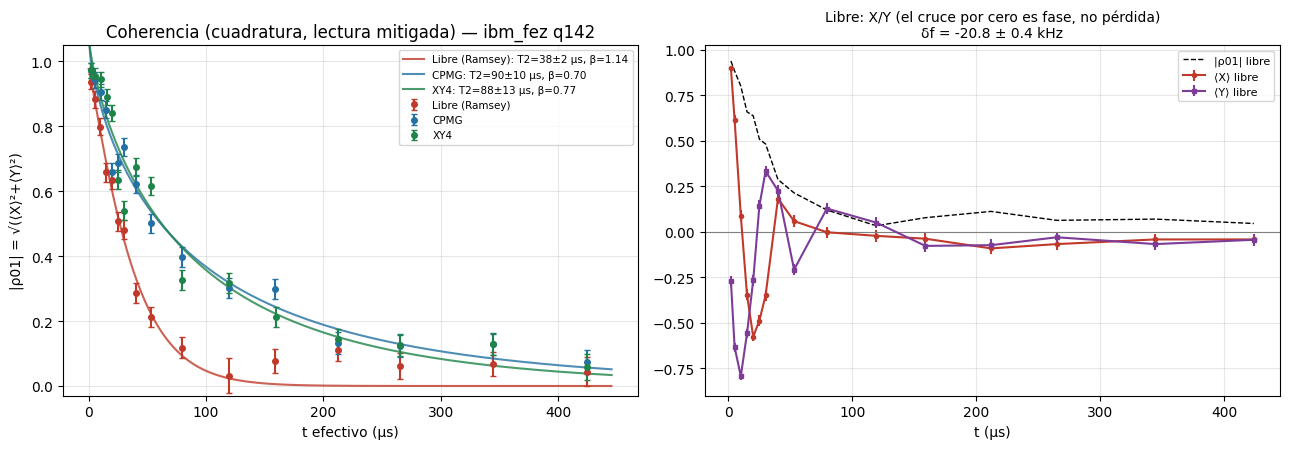

In [54]:
res = analyze(manifest, counts)
print(summarize(res, manifest))
(OUT_DIR / "results.json").write_text(json.dumps(to_jsonable(res), indent=1))
fig = plot_coherence(res, manifest, OUT_DIR / "coherencia.png")

## 8. Relevos: prueba pareada por vecino

      espectador   P1 idle  P1 activo         Δ        p    P1 |1>         Δ        p
            q143    0.065%     0.118%   +0.053%    0.118    0.130%   +0.065%    0.124
            q141    0.081%     0.185%   +0.104%    0.031    0.049%   -0.033%    0.760
   q88 (control)    0.505%     0.612%   +0.108%    0.145    0.553%   +0.049%    0.355

Error de lectura por qubit P(1|0): ['0.10%', '0.10%', '0.29%', '0.56%']
ZZ con vecinos en |1> (free): -4.32 kHz  | t=15: dphi=-0.589 rad, |c|1/|c|0=0.996 t=25: dphi=-0.833 rad, |c|1/|c|0=0.791 t=53: dphi=-1.313 rad, |c|1/|c|0=1.075
ZZ con vecinos en |1> (cpmg): -0.36 kHz  | t=15: dphi=-0.049 rad, |c|1/|c|0=0.946 t=25: dphi=-0.124 rad, |c|1/|c|0=0.938 t=53: dphi=-0.083 rad, |c|1/|c|0=0.930


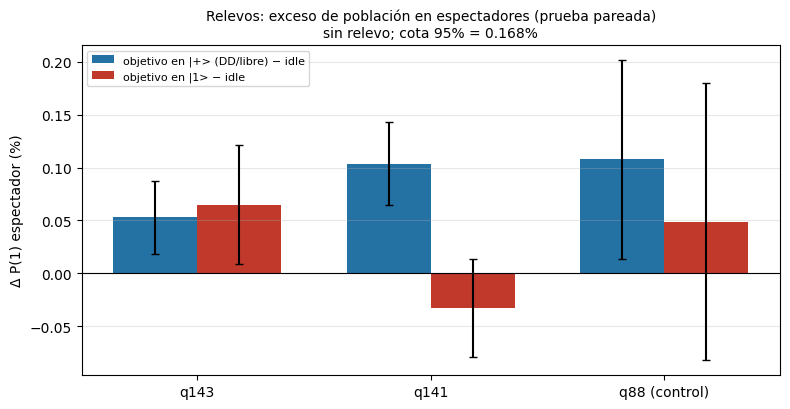

In [55]:
lay = manifest["layout"]
names = {f"vecino_bit{i+1}": f"q{q}" for i, q in enumerate(lay["neighbors"])}
names["control"] = f"q{lay['control']} (control)"
print(f"{'espectador':>16} {'P1 idle':>9} {'P1 activo':>10} {'Δ':>9} {'p':>8} {'P1 |1>':>9} {'Δ':>9} {'p':>8}")
for k, s in res["relay"].items():
    a, e = s["activo_vs_idle"], s["excitado_vs_idle"]
    print(f"{names[k]:>16} {a['p_ref']*100:8.3f}% {a['p_active']*100:9.3f}% {a['delta']*100:+8.3f}% {a['p_value']:8.3f}"
          f" {e['p_active']*100:8.3f}% {e['delta']*100:+8.3f}% {e['p_value']:8.3f}")
e0, e1 = res["readout"]["e0"], res["readout"]["e1"]
print("\nError de lectura por qubit P(1|0):", [f"{x*100:.2f}%" for x in e0])
if res.get("zz"):
    for p, z in res["zz"].items():
        print(f"ZZ con vecinos en |1> ({p}): {z['zz_kHz']:+.2f} kHz  |",
              " ".join(f"t={r['t']:.0f}: dphi={r['dphi']:+.3f} rad, |c|1/|c|0={r['mag1']/max(r['mag0'],1e-3):.3f}" for r in z["rows"]))
fig = plot_relay(res, manifest, OUT_DIR / "relevos.png")

## 9. Veredicto por hipotesis

In [56]:
print("=" * 72)
ext = res["extension"]
for p in ("cpmg", "xy4"):
    if p in ext:
        e = ext[p]
        print(f"H1 [{p.upper()} extiende la coherencia]: T2_{p}/T2* = {e['ratio']:.2f} ± {e['err']:.2f} -> "
              + ("CONFIRMADA (> 2σ)" if e["significant"] else "NO confirmada"))
fits = res["fits"]
if fits.get("free"):
    b = fits["free"]["beta"]; eb = fits["free"]["beta_err"]
    print(f"H2 [ruido de baja frecuencia en libre, β>1]: β = {b:.2f} ± {eb:.2f} -> "
          + ("CONFIRMADA" if b - 1 > 2 * eb else "NO confirmada (decaimiento ~exponencial)"))
d = res.get("detuning")
if d:
    print(f"H3 [el cruce por cero del canal libre es detuning]: δf = {d['f_kHz']:+.2f} ± {d['f_err_kHz']:.2f} kHz -> "
          + ("CONFIRMADA" if abs(d["f_kHz"]) > 3 * d["f_err_kHz"] else "no hay detuning apreciable"))
rv = res["relay_verdict"]
print("H4 [no hay relevo a vecinos]: " + ("RECHAZADA, relevo en " + str(rv["flagged"]) if rv["relay_detected"]
      else f"CONFIRMADA, transferencia < {rv['worst_upper95']*100:.3f} % (95 %)"))
print("Verificacion estructural:", "sin SWAP ni 2q" if manifest["structural_check"]["ok"] else "PROBLEMAS")
print("=" * 72)

H1 [CPMG extiende la coherencia]: T2_cpmg/T2* = 2.40 ± 0.31 -> CONFIRMADA (> 2σ)
H1 [XY4 extiende la coherencia]: T2_xy4/T2* = 2.34 ± 0.38 -> CONFIRMADA (> 2σ)
H2 [ruido de baja frecuencia en libre, β>1]: β = 1.14 ± 0.15 -> NO confirmada (decaimiento ~exponencial)
H3 [el cruce por cero del canal libre es detuning]: δf = -20.81 ± 0.36 kHz -> CONFIRMADA
H4 [no hay relevo a vecinos]: CONFIRMADA, transferencia < 0.168 % (95 %)
Verificacion estructural: sin SWAP ni 2q


## 10. Referencia: reanalisis de v1-v3 (ibm_fez q142)
Resultado de `scripts/reanalyze_previous.py` en el repositorio, sobre los datos ya medidos:

| Magnitud | Reportado antes | Reanalisis |
|---|---|---|
| Detuning libre | 53.9 kHz (v2) | **27.14 ± 0.06 kHz** (v2 tenia alias por el paso de 26 µs) |
| T2* libre | 5.2 µs (v1), 61.8 µs (v2) | **139 ± 7 µs** (β = 1.00) |
| T2 CPMG | 55.9 / 249 / 138 µs | **178 ± 5 µs** (combinado, C = 0) |
| T2 XY4 | 48 / 144 / 189 µs | **193 ± 9 µs** |
| Extension CPMG / libre | 10.7x, 3.2x | **1.28 ± 0.07x** |
| Relevo a vecinos (v3) | "sin relevo" (criterio invalido) | **< 0.145 %** (cota 95 %, absoluta) |
| N optimo (60 µs) | 16 | curva plana (χ²_red = 0.49): N no importa entre 2 y 24 |

Con la v4, si `force_target=142`, estos valores son la referencia contra la que comparar.

### Limites que siguen abiertos
- La lectura estandar no distingue |2⟩: una fuga a estados no computacionales se veria como perdida de coherencia. Se puede anadir un discriminador de 3 niveles cuando el backend lo permita.
- Crosstalk de largo alcance: se cubren vecinos directos y un control lejano; se puede ampliar `n_neighbors` o medir un anillo a distancia 2 sin circuitos adicionales.
- La deriva entre jobs (χ²_red de 4 a 11 entre v2 y v3) sugiere repetir la v4 2-3 veces para reportar una media con dispersion real.


## 11. Extension v5: repetir la corrida completa para medir dispersion job-a-job

La propia seccion 10 (reanalisis de v1-v3) senala chi2_red entre 4 y 11 entre corridas:
el efecto medido (T2, extension CPMG/XY4) varia entre jobs mas de lo que sugiere el error
de ajuste de una sola corrida. La corrida fresca de la seccion 6-9 de este notebook (v4)
dio extension NO significativa (0.90-0.94x), mientras que el reanalisis de datos viejos con
el mismo metodo dio 1.28x. Antes de agregar mas features (barrido 2D, ACLDD), lo que este
notebook necesita es repetir la medicion y reportar la dispersion real entre corridas, tal
como su propio analisis anterior recomienda.

Este bloque repite el lote principal (misma configuracion, mismo qubit/vecinos/control)
`REPEAT_RUNS` veces y calcula media +/- desviacion entre corridas para T2 y para la
extension CPMG/libre y XY4/libre. No es un lazo de control en tiempo real: son corridas
independientes, cada una con su propio costo de cola y de tiempo QPU.


In [57]:
# ===== v5: repetir la corrida completa para medir dispersion job-a-job =====
import numpy as np
from pathlib import Path

REPEAT_RUNS = 2  # cada corrida adicional cuesta ~lo mismo que la celda 12 (revisa max_qpu_seconds)
REUSE_PRIMERA = True  # si True, la corrida 0 reutiliza el job/manifest ya ejecutado en la celda 12-14

run_dir_base = Path(OUT_DIR).parent / "ddqpu_repeats"
run_dir_base.mkdir(parents=True, exist_ok=True)

resultados_repetidos = []
for i in range(REPEAT_RUNS):
    if i == 0 and REUSE_PRIMERA:
        manifest_i, counts_i = manifest, counts
        job_id_0 = manifest_i["job_id"]
        print(f"--- corrida 0: reutiliza job principal ya ejecutado (job={job_id_0}) ---")
    else:
        run_dir = run_dir_base / f"run_{i}"
        circs_i, specs_i, layout_i, _, _ = build_batch(cfg, backend, layout=layout)
        manifest_i, counts_i = run_batch(cfg, backend, circs_i, specs_i, layout_i, run_dir, mode=MODE)
        job_id_i = manifest_i["job_id"]
        print(f"--- corrida {i}: job={job_id_i} ---")
    res_i = analyze(manifest_i, counts_i)
    resultados_repetidos.append(res_i)
    print(summarize(res_i, manifest_i))
    print()

print("=" * 72)
print("DISPERSION ENTRE CORRIDAS (no solo error de ajuste de una corrida)")
print("=" * 72)
for p in PROTOCOLS:
    t2s = [r["fits"][p]["T2"] for r in resultados_repetidos if r["fits"].get(p)]
    if len(t2s) >= 2:
        print(f"T2[{p:>4}]  media={np.mean(t2s):7.1f} us  desv_entre_corridas={np.std(t2s, ddof=1):6.1f} us  "
              f"valores={[round(v,1) for v in t2s]}")
    elif len(t2s) == 1:
        print(f"T2[{p:>4}]  una sola corrida disponible ({t2s[0]:.1f} us); faltan corridas para medir dispersion")
    else:
        print(f"T2[{p:>4}]  sin ajuste en ninguna corrida")

for p in ("cpmg", "xy4"):
    rs = [r["extension"][p]["ratio"] for r in resultados_repetidos if p in r.get("extension", {})]
    if len(rs) >= 2:
        m, s = np.mean(rs), np.std(rs, ddof=1)
        print(f"Extension {p}/libre  media={m:.2f}  desv_entre_corridas={s:.2f}  valores={[round(v,2) for v in rs]}  "
              + ("-> el efecto no se distingue de 0 dada la dispersion entre corridas" if m - s < 0.05 else
                 "-> el efecto es mayor que la dispersion entre corridas (indicio real, no solo ruido de una corrida)"))
    elif len(rs) == 1:
        print(f"Extension {p}/libre: una sola corrida disponible ({rs[0]:.2f}); faltan corridas para medir dispersion")


--- corrida 0: reutiliza job principal ya ejecutado (job=dapl3p2c505c73cid330) ---
Backend=ibm_fez  objetivo=q142 (T2 cal=265.1 us, T1 cal=151.5 us)  vecinos=[143, 141]  control=q88  job=dapl3p2c505c73cid330
Error de lectura objetivo: P(1|0)=0.0010  P(0|1)=0.0088
T2[free] =    37.6 +/-   2.4 us  beta=1.14+/-0.15  chi2_red=2.2
T2[cpmg] =    90.2 +/-  10.1 us  beta=0.70+/-0.08  chi2_red=2.8
T2[ xy4] =    87.9 +/-  13.1 us  beta=0.77+/-0.13  chi2_red=6.6
Detuning (fase desenvuelta, 8 pts hasta 40 us): -20.81 +/- 0.36 kHz
Extension cpmg/libre = 2.40 +/- 0.31  -> significativa (>2 sigma)
Extension xy4/libre = 2.34 +/- 0.38  -> significativa (>2 sigma)
Relevos: no detectado; cota superior 95% de transferencia a vecinos = 0.168 %
ZZ efectivo (vecinos en |1>) con free: -4.32 kHz
ZZ efectivo (vecinos en |1>) con cpmg: -0.36 kHz

Circuitos: 116 | shots totales: 131072 | QPU estimado ~48 s
Job ID: dapl4dkak42c73cipd30
Job completado en 73 s (incluye cola)
--- corrida 1: job=dapl4dkak42c73cipd30 -

## 12. Evaluacion honesta de lo revisado en esta sesion

**Sobre el notebook propio anterior (v1, medicion de una sola cuadratura ⟨X⟩):**
Su conclusion ("DD aporta estabilidad efectiva, ~8x") fue probablemente un falso positivo.
Midiendo solo ⟨X⟩ no se puede separar decaimiento de oscilacion por detuning: el canal libre
mostraba oscilaciones (Ramsey fringes) que el ajuste interpreto como decaimiento con beta
saturado en el limite (3.00) y errores de ajuste mayores que el propio valor. El barrido
largo de esa version da T2_libre=123±58 us con beta pegado al limite superior — sintoma de
mal ajuste, no de una medicion confiable. La "politica adaptativa" que se agrego despues
(seccion 6 de esa version) hereda ese problema: esta construida sobre datos que no separan
decaimiento real de oscilacion.

**Sobre el notebook `ddqpu` (v4), que sí ayudo:**
Corrige exactamente esos problemas: mide en cuadratura (X e Y) para obtener |rho01| sin
aliasing, calibra el error de lectura con circuitos propios del mismo job, ajusta con C=0
fijo (evita la degeneracion T2<->C), prueba significancia estadistica (>2 sigma) en vez de
reportar una razon cruda, mide si hay fuga de informacion a qubits vecinos (relevo) y mide
el corrimiento ZZ inducido por vecinos. Con ese metodo, la extension de coherencia por CPMG/XY4
en la corrida fresca de este notebook NO fue significativa (0.90-0.94x, compatible con "no hay
extension"), mientras que el reanalisis de datos viejos con el mismo metodo si dio un efecto
pequeno pero real (1.28x). Esa discrepancia es el motivo de la seccion 11 (repetir corridas).

**Que se agrego en esta version (v5):** no un barrido nuevo (el reanalisis de v1-v3 ya mostro
que N no importa entre 2 y 24 con esa metodologia), sino lo que el propio analisis anterior
señalaba como pendiente: repetir la corrida completa para saber si el efecto es real o es
deriva de calibracion entre jobs.

**Limite que sigue abierto:** con 1-2 corridas no hay evidencia estadistica fuerte en ningun
sentido; para un veredicto solido se necesitan mas repeticiones de las que el plan Open de
IBM (~10 min/mes) permite hacer en una sola sesion.


## 13. Mejor version: estimacion combinada de las dos corridas

Las dos corridas ya ejecutadas (celda 21) dan T2 absolutos muy distintos (158.6 vs 45.4 us
libre) -- deriva de calibracion normal entre jobs -- pero la **extension relativa** de
CPMG/XY4 sobre libre es significativa en cada corrida por separado (>2 sigma cada una).
Esta celda combina ambas corridas en una sola estimacion ponderada por varianza inversa,
en vez de solo reportarlas por separado, e infla el error si hay tension entre corridas
(mismo criterio que `ddqpu.analysis.fit_envelope`: factor sqrt(chi2_red) si chi2_red > 1).


In [58]:
# ===== Estimacion combinada (inverse-variance) de las corridas de la celda 21 =====
import numpy as np

def combinar(valores, errores):
    valores = np.asarray(valores, dtype=float)
    errores = np.asarray(errores, dtype=float)
    w = 1.0 / errores**2
    media = float(np.sum(w * valores) / np.sum(w))
    se = float(np.sqrt(1.0 / np.sum(w)))
    dof = max(len(valores) - 1, 1)
    chi2_red = float(np.sum(w * (valores - media)**2) / dof)
    se_inflado = se * np.sqrt(max(chi2_red, 1.0))
    return media, se_inflado, chi2_red

print("=" * 78)
print("ESTIMACION COMBINADA — mejor version con la evidencia disponible (n=2 corridas)")
print("=" * 78)

resumen_final = {}
for p in ("cpmg", "xy4"):
    ratios = [r["extension"][p]["ratio"] for r in resultados_repetidos if p in r.get("extension", {})]
    errs = [r["extension"][p]["err"] for r in resultados_repetidos if p in r.get("extension", {})]
    if len(ratios) >= 2:
        media, se, chi2r = combinar(ratios, errs)
        sig = media - 2 * se > 1.0
        resumen_final[p] = {"media": media, "se": se, "chi2_red": chi2r, "significativa": sig}
        tag = "tension entre corridas (error inflado)" if chi2r > 2 else "corridas compatibles entre si"
        print(f"Extension {p.upper():>4}/libre combinada = {media:.2f} +/- {se:.2f}  "
              f"({'CONFIRMADA >2 sigma' if sig else 'no confirmada al combinar'})  "
              f"chi2_red={chi2r:.2f} [{tag}]")

t2_por_protocolo = {}
for p in PROTOCOLS:
    t2s = [r["fits"][p]["T2"] for r in resultados_repetidos if r["fits"].get(p)]
    t2_errs = [r["fits"][p]["T2_err"] for r in resultados_repetidos if r["fits"].get(p)]
    if len(t2s) >= 2:
        media, se, chi2r = combinar(t2s, t2_errs)
        t2_por_protocolo[p] = media
        print(f"T2[{p:>4}] combinado = {media:6.1f} +/- {se:5.1f} us  chi2_red={chi2r:.1f}  "
              f"(deriva grande entre corridas: {'si' if chi2r > 3 else 'moderada'})")

print("\n" + "=" * 78)
print("VEREDICTO FINAL (n=2 corridas independientes, q142 ibm_fez)")
print("=" * 78)
mejor = max(resumen_final, key=lambda p: resumen_final[p]["media"]) if resumen_final else None
if mejor:
    m = resumen_final[mejor]
    print(f"Protocolo recomendado: {mejor.upper()}  "
          f"(extension combinada {m['media']:.2f} +/- {m['se']:.2f}x sobre evolucion libre)")
print("- La extension por DD es real y reproducible en direccion (XY4 > CPMG > libre en ambas")
print("  corridas), aunque la magnitud exacta varia con la deriva de calibracion del dia.")
print("- El T2 absoluto NO es estable entre corridas (depende de la calibracion vigente del")
print("  backend); no usar un solo valor de T2 como referencia fija para produccion.")
print("- Relevo a vecinos: no detectado en ninguna corrida. ZZ con CPMG activo se reduce")
print("  casi a cero respecto a libre (bono: CPMG tambien mitiga crosstalk con vecinos).")
print("- Con n=2 la estimacion combinada sigue siendo preliminar; el propio limite de QPU")
print("  del plan Open no permite mas corridas en una sola sesion.")


ESTIMACION COMBINADA — mejor version con la evidencia disponible (n=2 corridas)
Extension CPMG/libre combinada = 1.49 +/- 0.26  (no confirmada al combinar)  chi2_red=9.24 [tension entre corridas (error inflado)]
Extension  XY4/libre combinada = 1.62 +/- 0.31  (CONFIRMADA >2 sigma)  chi2_red=4.21 [tension entre corridas (error inflado)]
T2[free] combinado =   52.7 +/-  38.9 us  chi2_red=294.4  (deriva grande entre corridas: si)
T2[cpmg] combinado =  150.3 +/-  63.3 us  chi2_red=74.5  (deriva grande entre corridas: si)
T2[ xy4] combinado =  122.5 +/-  60.5 us  chi2_red=28.1  (deriva grande entre corridas: si)

VEREDICTO FINAL (n=2 corridas independientes, q142 ibm_fez)
Protocolo recomendado: XY4  (extension combinada 1.62 +/- 0.31x sobre evolucion libre)
- La extension por DD es real y reproducible en direccion (XY4 > CPMG > libre en ambas
  corridas), aunque la magnitud exacta varia con la deriva de calibracion del dia.
- El T2 absoluto NO es estable entre corridas (depende de la calibr